# From two files to hotspots and lineages: the flagship workflow

This notebook runs spaclone's main workflow on a Stereo-seq section of a mouse spleen with its B-cell receptor contigs:

1. read the transcriptome and the receptor table (`spaclone.read`);
2. ask whether receptor positions can be trusted (`spaclone.run`), because every later map assumes they can;
3. find where class switching (CSR) and somatic hypermutation (SHM) concentrate, where the two overlap and what those
   places are made of in the transcriptome (`bcr.hotspot_workflow`, `pl.hotspot_atlas`, `pl.csr_map`), with the
   confirmatory clone-level SHM test;
4. build germline-rooted lineage trees whose tips sit on the tissue (`bcr.lineage_workflow`, `pl.lineage_tree`);
5. follow the class-switch potential over the tissue with sciCSR's transition model (`bcr.csr_potential`,
   `tl.transition_model`, `tl.tpt_flux`, `pl.csr_flow`);
6. place Threadfin's clone states on the tissue (`ext.threadfin.run`, `pl.clone_state_map`).

Every test states its null design next to its result. The whole notebook runs in about 12 minutes on 4 CPUs.

In [1]:
import time

t_start = time.time()

import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import spaclone
from spaclone import bcr, gex, pl, tl
from spaclone.ext import threadfin

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 100)
plt.rcParams["figure.dpi"] = 72  # screen resolution keeps the notebook small
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"  # one-line warnings
print("spaclone", spaclone.__version__)

spaclone 1.0.0


## The data

**StereoIR** is a Stereo-seq 5′ immune-repertoire demonstration data set of one mouse spleen section:

* `mm_spleen_bin20_anno.h5ad`: the transcriptome in bins of 20 × 20 DNBs (10 µm), with cell2location cell-type
  abundances and a label per bin (`cell2loc_anno`);
* `mm_spleen_bcr_airr.tsv.tsv`: the BCR contigs assembled by TRUST4, as an AIRR rearrangement table whose `cell_id`
  holds the bin position (the double extension is as distributed); `mm_spleen_tcr_airr.tsv.tsv` holds the TCR contigs.

The files are distributed as Stereo-seq demonstration data; we could not confirm a public download address when this
tutorial was written. Put them in one folder and set the environment variable `SPACLONE_STEREOIR` to it. Any section
with a spatial transcriptome and an AIRR table (TRUST4, Cell Ranger, IgBLAST / Change-O, MiXCR, ...) runs the same
way.

In [2]:
DATA = Path(os.environ.get("SPACLONE_STEREOIR", "."))
H5AD, BCR_AIRR = DATA / "mm_spleen_bin20_anno.h5ad", DATA / "mm_spleen_bcr_airr.tsv.tsv"

sa = spaclone.read(H5AD, BCR_AIRR)
air, G = sa.air, sa.gex
print(f"{len(air):,} BCR contigs on {air.spot_id.nunique():,} bins; transcriptome {G.n_obs:,} bins x {G.n_vars:,} genes")
print("contigs per chain:", air["locus"].value_counts().to_dict())
print("bin labels:", G.obs["cell2loc_anno"].value_counts().to_dict())

145,511 BCR contigs on 65,905 bins; transcriptome 119,644 bins x 24,891 genes
contigs per chain: {'IGK': 89877, 'IGH': 43517, 'IGL': 12117}
bin labels: {'B_cells': 39453, 'Monocytes_Macrophages': 21555, 'Erythrocyte': 18225, 'T_cells': 17631, 'Dendritic_cells': 11077, 'Neutrophils': 7423, 'NK_cells': 4280}


`spaclone.read` recognised both files from their contents (`spaclone.io.sniff(path)` shows the evidence), turned the
bin positions into micrometres and matched every contig to its bin of the transcriptome.

## 1. Can the positions be trusted?

`spaclone.run` filters the records and runs every location-trust test the data allow. It answers at two levels, with
criteria fixed before the data are seen:

* **molecule level**: does a receptor sit on its own cell type (or its own constant-region transcript) more often than
  whole bins placed at random in proportion to their cDNA?
* **clone level**: do contigs of one clone sit together beyond what their local Ig RNA explains (clone labels shuffled
  within Ig RNA strata), and do heavy and light chains of one cell share bins beyond a chimera-aware null?

Only the clone level licenses clone maps and spatial clone statistics. The bins carry cell-type labels
(`cell2loc_anno`); `run` uses such a column, and the B-lineage labels in it, when the choice is unambiguous.

In [3]:
rep = spaclone.run(sa)
print(rep.verdict_molecule)
print(rep.verdict_clone)
COLS = ["test", "level", "locus", "n", "observed", "chance", "ratio", "p_value", "q_value", "verdict"]
rep.tests()[COLS]

Molecule level: signal — molecules sit on their own transcript / cell type more often than random placement (own_type_share (BCR)).
Clone level: signal — clone identity follows position (colocalisation (IGH mm_spleen_bcr_airr); pairing (IGH/IGK mm_spleen_bcr_airr, IGH/IGL mm_spleen_bcr_airr); partner_sharing (IGH>IGK, IGH>IGL)).


,test,level,locus,n,observed,chance,ratio,p_value,q_value,verdict
0,own_type_share,molecule,BCR,143134.0,0.588043,0.329835,1.782841,0.004975,0.004975,signal
1,colocalisation,clone,IGH,42801.0,0.096695,0.004530,21.347033,0.004975,0.008292,signal
2,colocalisation,clone,IGK,88946.0,0.052384,0.004223,12.403381,0.004975,NaN,info
3,colocalisation,clone,IGL,12023.0,0.047526,0.004873,9.753247,0.004975,NaN,info
4,pairing,clone,IGH/IGK,42801.0,12.048134,3.364208,3.581269,0.004975,0.008292,signal
5,pairing,clone,IGH/IGL,42801.0,3.560955,1.979079,1.799299,0.004975,0.008292,signal
6,partner_sharing,clone,IGH>IGK,1807.0,0.349198,0.180457,1.935073,0.010000,0.010000,signal
7,partner_sharing,clone,IGH>IGL,654.0,0.551988,0.436020,1.265968,0.010000,0.010000,signal
8,barcode_sinks,info,,49.0,0.007216,NaN,NaN,NaN,NaN,info
9,same_spot,molecule,,NaN,NaN,NaN,NaN,NaN,NaN,not run


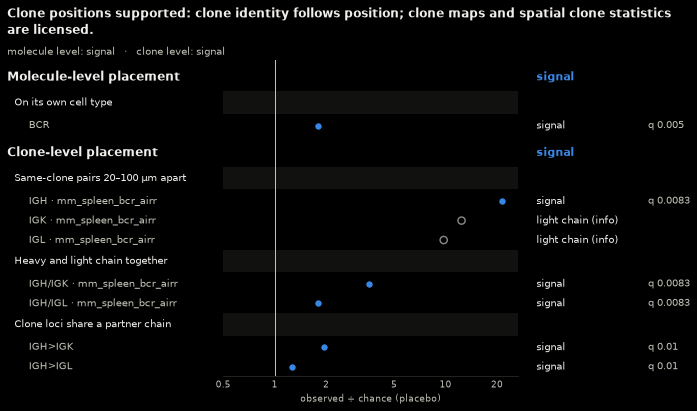

In [4]:
fig = rep.plot()
plt.show()

*Reading the report.* At the **molecule level**, 59% of the BCR contigs sit on bins labelled B cells, against 33%
when whole bins are placed at random in proportion to their cDNA (1.8×, q = 0.005); `run` found the label column
(`cell2loc_anno`) and its B-lineage label (`B_cells`) on its own. The same-spot test is not run: a 10 µm bin is about
the size of a cell, so every bin holds the constant-region RNA of its cells and of their neighbours whatever the
receptor does. At the **clone level**, IGH contigs of one clone sit 20–100 µm apart 21 times more often than clone
labels shuffled within Ig RNA strata give (q = 0.008); heavy and light chains share bins 3.6 (kappa) and 1.8 (lambda)
times more often than chimera-aware shuffles allow; and the loci of one heavy clonotype share their light-chain partner
1.9 and 1.3 times more often than chance. Light-chain co-localisation (10–12×) is information only. Both levels pass,
so clone maps and spatial clone statistics are licensed for this section. Barcode sinks are few: 49 bins with 0.7% of
the contigs.

## 2. Class-switch and mutation hotspots

`bcr.hotspot_workflow` does the whole analysis on the heavy chains:

1. **records**: valid, productive IGH contigs with at least 2 reads (`min_reads="auto"` picks 2 for contigs, 1 for
   single molecules); clones = V gene + J gene + junction amino acids; isotype and switched call; V-gene mutations
   against the allele baseline;
2. **loci**: same-clone bins within 15 µm merged into one inferred cell, switched or mutated by majority;
3. **maps and hotspots**: kernel maps (σ = 50 µm) of the switched share and of the mutated share; a hotspot is a
   connected set of pixels above the 95th percentile of the shuffled maps' maxima, so the chance of any false hotspot
   on the map is 5%;
4. **CSR ∩ SHM regions**: CSR hotspots whose outlines touch an SHM hotspot, with clone-level p-values (whole clones
   relabelled, because the loci of an expanded clone share their isotype and mutations);
5. **GEX**: what each region is made of, from the transcriptome alone (marker pseudobulk inside the region against
   its surroundings).

The run takes about two minutes.

In [5]:
hot = bcr.hotspot_workflow(sa)
print(hot)
hot.summary()

HotspotWorkflowResult(37,690 IGH records, 31,516 loci; 12 CSR and 8 SHM hotspots; 3 CSR∩SHM regions: 1: plasmablast/ASC (clone-level p CSR 1, SHM 0.974); 2: plasmablast/ASC (clone-level p CSR 0.57, SHM 1); 3: plasmablast/ASC (clone-level p CSR 0.018, SHM 1))


,step,item,value,note
0,records,receptor records,145511,input
1,records,"valid junction (C...W/F, 20 aa, >= 5 aa)",144815,
2,records,productive,144815,
3,records,reads >= 2,136793,"min_reads auto: 2, contigs or read-counted clones (reade..."
4,records,IGH (heavy chain),37690,units of the CSR / SHM analysis
5,records,loci,31516,same-clone spots within 15 um merged
6,records,loci on the map grid,31514,GEX units (all)
7,loci,loci,31516,
8,loci,isotyped loci on the grid,26100,
9,loci,evaluable loci on the grid,14058,


*Reading the summary.* 37,690 IGH contigs with at least 2 reads form 31,516 loci; 26,100 of them have an isotype
(16% switched) and 14,058 enough reads and aligned V for a mutation call (7.3% mutated). The switched-share map has 12
CSR hotspots (0.13 mm² in all; family-wise threshold z = 5.1, highest z = 10) and the mutated-share map 8 SHM hotspots
(0.07 mm²). Three regions hold both, and all three are plasmablast / ASC areas by their transcriptome.

The clone-level columns are the stringent reading: when whole clones are relabelled, only region 3 keeps its CSR
hotspot at the map level (p = 0.018), and no SHM hotspot survives (map-level p of the highest peak 0.36).
`shm_clone_region_p` (0.0005–0.03) is descriptive, because the regions were chosen for touching an SHM hotspot.

The regions, with their GEX answer:

In [6]:
hot.regions[["region_id", "csr_hotspots", "shm_hotspots", "n_loci", "switched_share", "mutated_share",
             "csr_clone_p", "shm_clone_p", "shm_clone_region_p", "gex_label", "gex_ratio_window"]]

,region_id,csr_hotspots,shm_hotspots,n_loci,switched_share,mutated_share,csr_clone_p,shm_clone_p,shm_clone_region_p,gex_label,gex_ratio_window
0,1,4,1,180,0.392857,0.325301,1.000000,0.974026,0.000500,plasmablast/ASC,4.507309
1,2,1,5;6,309,0.394191,0.217391,0.570430,1.000000,0.007299,plasmablast/ASC,4.690251
2,3,3,3,194,0.433333,0.315068,0.017982,1.000000,0.026697,plasmablast/ASC,7.577248


`pl.hotspot_atlas` draws the section with every CSR and SHM hotspot and zooms on the regions where they overlap,
each with its loci and the GEX modules around it:

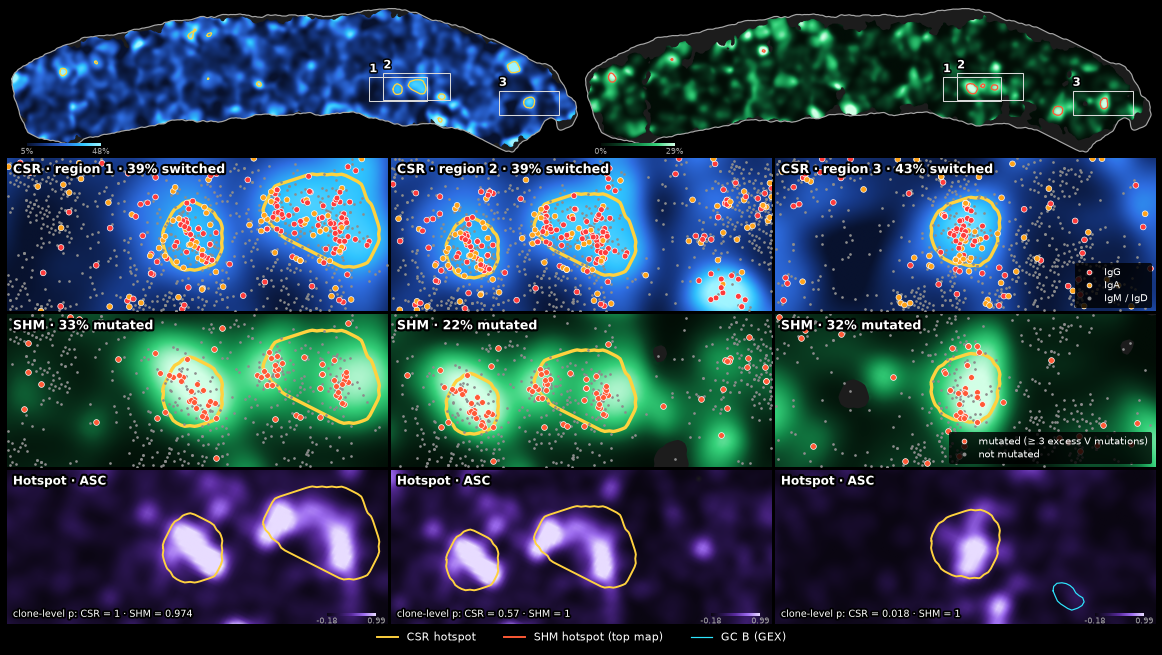

In [7]:
fig = pl.hotspot_atlas(hot, dpi=72)
plt.show()

`pl.csr_map` is the tissue counterpart of sciCSR's class-switch views: where each isotype sits along the IgH locus
order, and which switches the clones show (arcs between isotypes found together in one clone):

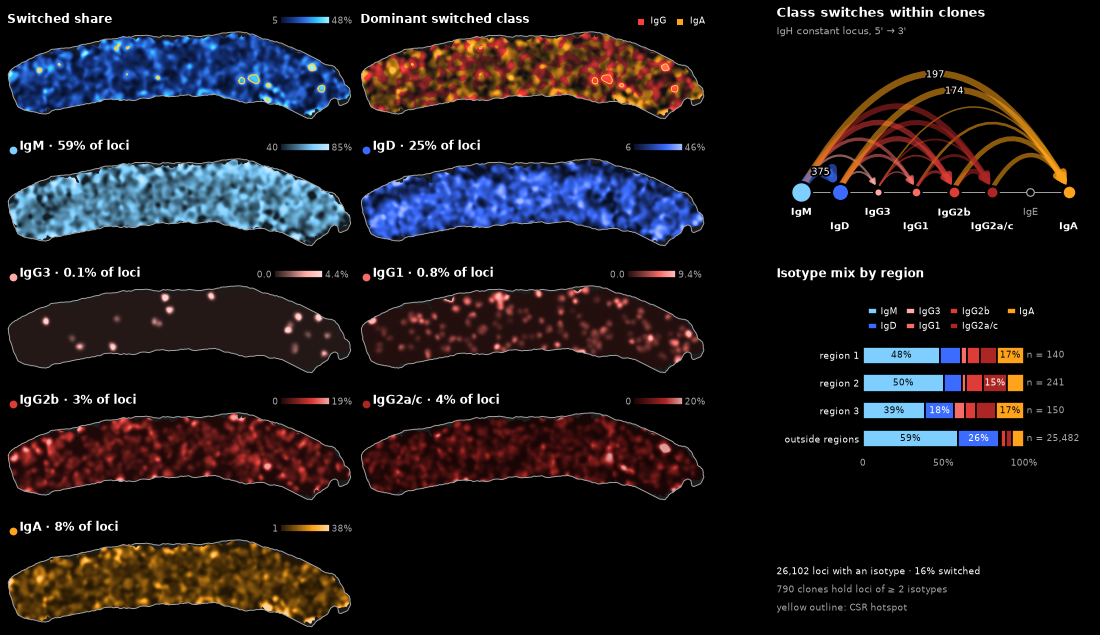

In [8]:
fig = pl.csr_map(hot, dpi=72)
plt.show()

### The confirmatory SHM test: `csr_shm_clone`

The regions above were selected because they touch an SHM hotspot, so their own SHM p-values (`p`,
`shm_clone_region_p`) describe the excess rather than test it. The confirmatory test turns this around: every CSR
hotspot is found from the switched calls alone, and is then tested for more mutated loci than its isotypes *and* clone
sizes predict. The null relabels whole clones (clones trade their mutated calls only with clones of the same size and
isotype mix; hotspots fixed), and q-values are corrected over the CSR hotspots.

In [9]:
t = hot.csr_shm_clone.table
t[["csr_hotspot", "units", "marked", "null_mean", "ratio", "p_value", "q_value"]]

,csr_hotspot,units,marked,null_mean,ratio,p_value,q_value
0,1,138,30,21.2344,1.331485,0.004800,0.014399
1,2,14,3,2.4594,0.928933,0.471253,0.565503
2,3,73,23,16.9668,1.637520,0.025797,0.051595
3,4,83,27,15.9214,2.451610,0.000700,0.004200
4,5,6,0,0.5765,0.000000,1.000000,1.000000
5,10,5,3,1.0433,2.526511,0.044696,0.067043
6,all,331,90,62.3123,1.602325,0.000100,NaN


Six CSR hotspots have at least 5 evaluable loci. Pooled, they hold 90 mutated loci of 331 against 62 expected from
their isotypes and clone sizes (p = 0.0001), and two pass BH on their own: hotspot 4 (region 1; 27 of 83 loci mutated
against 16 expected, q = 0.004) and hotspot 1 (region 2; 30 of 138 against 21, q = 0.014). Hotspot 3 (region 3) is
just above the line (q = 0.052). Places selected for class switching alone therefore also carry more mutation than
their isotypes and clone sizes explain, and the transcriptome calls them plasmablast / ASC areas.

## 3. Lineage trees on the tissue

`bcr.lineage_workflow` builds germline-rooted parsimony trees from the contig sequences, one per clone (`"exact"`:
same V gene, J gene and junction) and one per group of related clones (`"related"`: same V and J genes, junctions at
least 85% identical), and places every tip on the tissue with its isotype, its mutations and its location class (CSR
hotspot, follicle, T zone, red pulp). Given the hotspot result, it reuses its records, its CSR hotspots and its
transcriptome.

In [10]:
lin = bcr.lineage_workflow(hot)
print(lin)
lin.summary()

LineageWorkflowResult(exact: 66 trees, 2300 tips, 16 drawn; related: 107 trees, 3700 tips, 16 drawn)


,grouping,clones,trees,tips,tips_in_trees,tree_tips,eligible,drawn
0,exact,14128,66,2300,2298,1234,47,16
1,related,12020,107,3700,3690,2109,82,16


The trees are ranked by their most mutated tip, and the first ones of each grouping are drawn:

In [11]:
drawn = lin.drawn()
drawn.groupby("grouping").head(3)[["grouping", "tree_id", "n_tips", "n_loci", "max_mutations", "n_exact_clones",
                                   "rank"]]

,grouping,tree_id,n_tips,n_loci,max_mutations,n_exact_clones,rank
0,exact,IGHV1-26|IGHJ4|CARYGNYDAMDYW,17,16,17,1,1
1,exact,IGHV1-81|IGHJ1|CAREAGTGRYFDVW,38,33,15,1,2
2,exact,IGHV1-81|IGHJ3|CARLRGYAWFAYW,25,25,15,1,3
16,related,IGHV1-26|IGHJ4|CARYGNYDAMDYW,34,33,17,13,1
17,related,IGHV1-81|IGHJ1|CAREAGTGRYFDVW,49,44,15,8,2
18,related,IGHV1-81|IGHJ3|CARLRGYAWFAYW,27,27,15,3,3


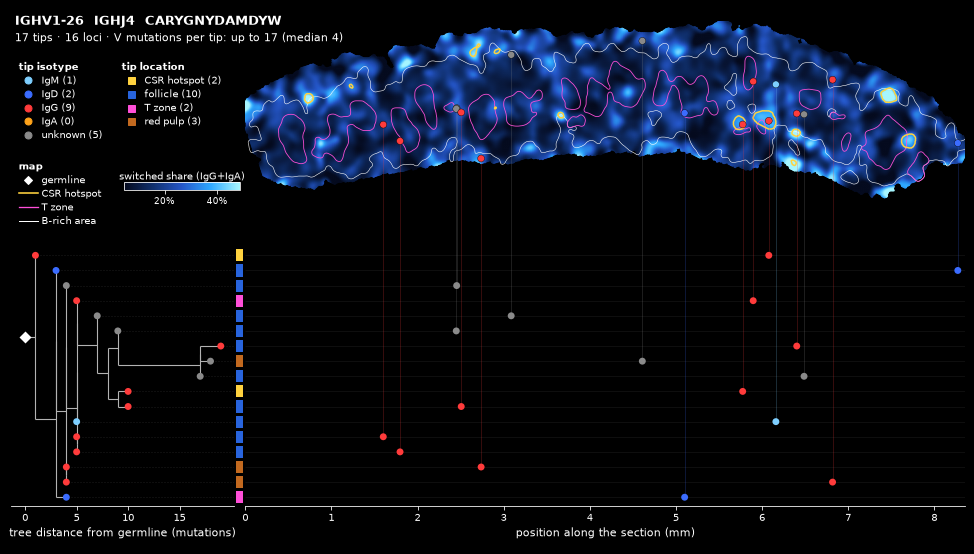

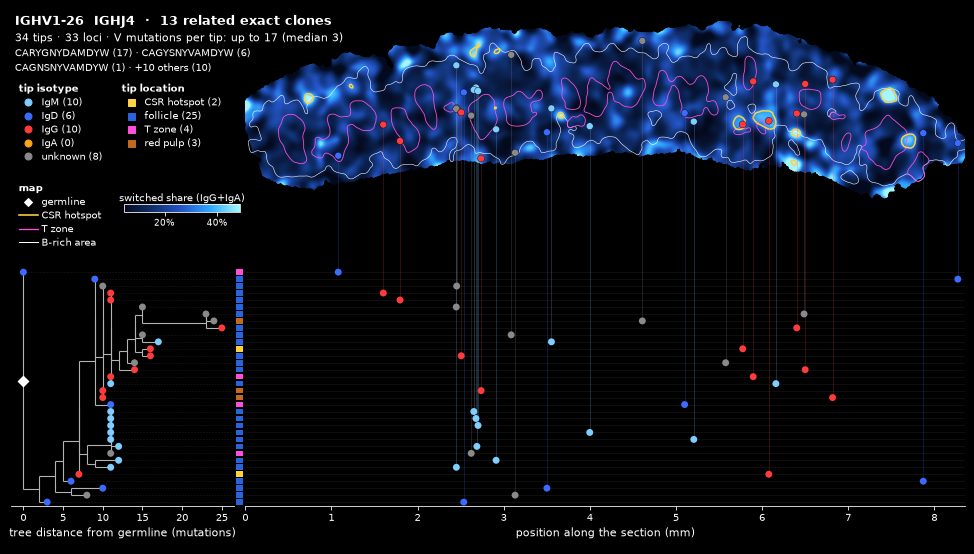

In [12]:
for grouping in ("exact", "related"):
    tree_id = lin.drawn(grouping).tree_id.iloc[0]
    fig = pl.lineage_tree(lin, tree_id, grouping=grouping)
    plt.show()

Each figure shows one tree. Left: the germline-rooted tree (x = mutations from the germline along the tree, tips
coloured by isotype, squares by location class). Top right: the section, with the tips at their bins over the
switched-share map. Bottom right: each tip's position along the section, on the row of its tree tip. The most mutated
exact clone (IGHV1-26, IGHJ4, CARYGNYDAMDYW) has 17 tips in 16 loci, 9 of them IgG, spread over most of the 8 mm
section: its switched and mutated members are not confined to one place. The related group of the same rank joins 13
exact clones of this V–J pair with similar junctions (34 tips), so related clones extend the lineage that one exact
clone shows. `pl.lineage_gallery(lin, folder)` writes every drawn tree to image files.

## 4. sciCSR on tissue: where does the class-switch potential flow?

sciCSR (Ng et al., *Nat Methods* 2023) gives every cell a **CSR potential**, the position of its isotype along the IgH
locus (scaled to 0–1), and builds a Markov chain on a neighbour graph whose steps prefer neighbours of higher potential.
Transition path theory (TPT) then measures how this chain carries probability from a source state to a target state,
and through which intermediate states. spaclone runs the same construction on tissue units with a spatial graph.

A unit here is a 50 µm tile: its isotype is the most frequent one among its heavy-chain contigs (`mode="highest"`),
tiles without an isotyped contig vote with their 15 nearest tiles, and its state is the main tissue region of its bins,
called from the transcriptome (`gex.call_regions`: germinal centres, plasma-cell areas, T zones, red pulp, follicles).
Tiles keep the chain small enough for a randomisation test.

In [13]:
TILE_UM = 50.0


def tile_of(x, y):
    """Id of the 50 µm tile holding each point."""
    return (np.floor(np.asarray(x) / TILE_UM).astype(int).astype(str) + "_"
            + np.floor(np.asarray(y) / TILE_UM).astype(int).astype(str))


rec = hot.records.assign(tile=tile_of(hot.records["x_um"], hot.records["y_um"]))
pot = bcr.csr_potential(rec, unit_key="tile", mode="highest", species="mouse")

regions = G.copy()  # region calls go into a copy, so the reader's transcriptome stays as it was
for kind in ("germinal_centre", "plasma_cell", "t_zone", "red_pulp", "follicle"):
    gex.call_regions(regions, kind=kind, layer="counts", tissue_key=None, cell_type_key="cell2loc_anno")
xy = regions.obsm["spatial"]
bin_region = pd.Series(regions.obs["region"].astype(str).to_numpy(), index=tile_of(xy[:, 0], xy[:, 1]))
tile_region = bin_region.groupby(level=0).agg(lambda s: s.value_counts().index[0])
pot["region"] = tile_region.reindex(pot.index).fillna("other").to_numpy()
print(f"{len(pot):,} tiles; isotypes:", pot["isotype"].value_counts().to_dict())
pot.groupby("region")["csr_pot"].agg(["size", "mean"]).round(3)

4,489 tiles; isotypes: {'IgM': 3809, 'IgA': 421, 'IgG2c': 121, 'IgG2b': 107, 'IgG1': 26, 'IgG3': 5}


,size,mean
region,,
ASC,289,0.119
GC,496,0.114
T zone,636,0.116
follicle,1902,0.096
red pulp,1166,0.187


The transition model biases each tile's steps towards neighbours of higher CSR potential (sciCSR's pseudotime kernel,
weight 0.8, on the 30 nearest tiles). TPT runs from the follicles (where unswitched B cells live) to the red pulp
(where plasma cells end up). The null permutes the CSR potential among the tiles of each region, so every region
keeps its own isotype mix and the graph stays fixed: a flux is significant when the *arrangement* of the potential on
the tissue carries more flux between two regions than the regions' isotype mixes alone (100 draws; BH over the pairs
of regions).

In [14]:
model = tl.transition_model(pot, time_key="csr_pot", graph="spatial", k=30, states="region", rng=0)
flux = tl.tpt_flux(model, source="follicle", target="red pulp", n_random=100, rng=0)
print(model)
print({k: flux.summary[k] for k in ("total_flux", "rate", "rate_p_value", "n_significant") if k in flux.summary})
flux.table.sort_values("net_flux", ascending=False).head(8)[
    ["from_state", "to_state", "net_flux", "statistic", "null_mean", "p_value", "q_value"]]

TransitionModel(4485 units, graph='spatial', time='csr_pot', weight=0.8, scheme='hard', 5 states)
{'total_flux': 0.05212604244226472, 'rate': 0.07699380757246023, 'rate_p_value': 0.019801980198019802, 'n_significant': 0}


,from_state,to_state,net_flux,statistic,null_mean,p_value,q_value
15,follicle,red pulp,63.782143,0.040720,0.040136,0.029703,0.396040
7,GC,red pulp,9.732677,0.006214,0.006076,0.059406,0.396040
13,follicle,GC,9.489479,0.006058,0.005908,0.049505,0.396040
12,follicle,ASC,7.292704,0.004656,0.004782,0.960396,1.000000
3,ASC,red pulp,7.269068,0.004641,0.004758,0.970297,1.000000
14,follicle,T zone,1.084640,0.000692,0.000673,0.148515,0.673267
11,T zone,red pulp,0.865078,0.000552,0.000529,0.168317,0.673267
0,ASC,GC,0.250349,0.000160,0.000168,0.722772,1.000000


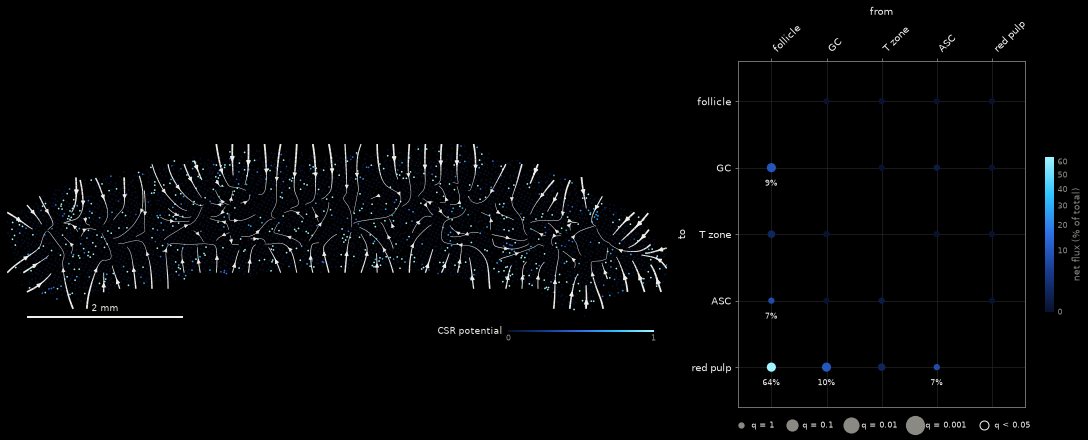

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2.3, 1]}, layout="constrained")
pl.csr_flow(model, kind="stream", label="CSR potential", ax=axes[0])
order = [s for s in ("follicle", "GC", "T zone", "ASC", "red pulp", "other") if s in set(flux.table.from_state)]
pl.flux_matrix(flux, value="net", order=order, ax=axes[1])
plt.show()

*Reading the flow.* The streamlines show where the chain moves on average: towards tiles of higher CSR potential.
TPT from follicle tiles to red-pulp tiles routes 64% of the net flux directly between the two, about 10% through GCs
and 7% through plasma-cell areas. The overall rate of reactive paths is higher than with the CSR potential permuted
within regions (p = 0.02, 100 draws), but no single pair of regions passes BH (smallest q = 0.40): the arrangement of
isotypes favours the follicle-to-red-pulp direction as a whole, with no route that stands out. Four tiles outside the
main component of the graph were left out (the warning above). The chain models where the potential increases on the
tissue; it is not a measurement of cell migration.

## 5. Threadfin clone states in space

Threadfin summarises each expanded clone by the transcriptomes of its units: a clone's position on a few axes of
clone-level variation, and programmes of clones that look alike. `ext.threadfin.run` runs it on the spatial units
(here bins with a heavy-chain clone, `units="spot"`, expression features), finds the tissue context (compartments and
distances) from the bin labels, and maps every clone's axis value back onto the tissue. It takes a few minutes.

In [16]:
tf = threadfin.run(sa, rng=0)
print(tf)
print(tf.context_note)
pd.Series(tf.summary())

ThreadfinSpatialResult(spot/expression: 33,271 units, 33,271 with a clone, 19,869 clones, 3,344 profiled; axis 1 56.0%, axis 2 8.1%, axis 3 5.4%)
auto: spatial_context(gex, cell_type_key='cell2loc_anno'), the only standard label column (T: T_cells; B: B_cells; erythroid: Erythrocyte)


units                      spot
features             expression
n_units                   33271
n_clonal_units            33271
n_clones                  19869
n_profiled_clones          3344
n_profiled_units          16746
icc                    0.052547
icc_p                  0.004975
n_programmes                  2
axis_1_share           0.560438
axis_2_share           0.080606
axis_3_share           0.053672
dtype: object

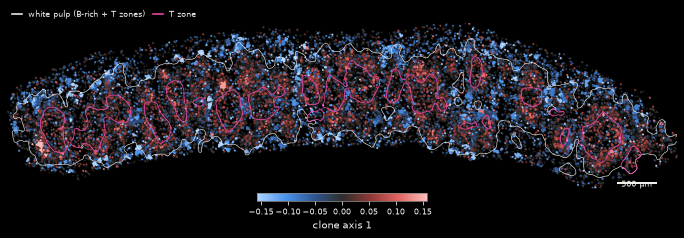

,count,mean
compartment,,
T zone,2364,0.014
follicle,10613,-0.010
red pulp,3769,-0.053


In [17]:
fig, ax = plt.subplots(figsize=(12, 4.4))
pl.clone_state_map(tf, ax=ax)
plt.show()
tf.units.groupby("compartment", observed=True)["clone_axis_1"].agg(["count", "mean"]).round(3)

*Reading the clone states.* Of 33,271 bins with a heavy-chain clone, 16,746 belong to the 3,344 clones with enough
bins to be profiled. Clone identity explains a small but real share of the bins' transcriptomes (Threadfin's ICC 0.05,
p = 0.005), and axis 1 carries 56% of the clone-level variance. On the tissue, clones whose bins lie in the white pulp
(inside the white outline: B-rich areas and T zones) sit at one end of axis 1 (red) and clones of the red pulp at the
other (blue); the table gives the mean per compartment, from 0.014 in T zones and −0.010 in follicles to −0.053 in the red pulp. A 10 µm bin also holds RNA of its neighbours, so
axis 1 reads a clone's surroundings as much as the state of its B cells: it says where a clone's members live.

## Summary

| Step | Function | StereoIR spleen |
|---|---|---|
| Can positions be trusted? | `spaclone.run` | yes at both levels: own cell type 1.8×; IGH co-localisation 21×, heavy/light pairing 1.8–3.6× |
| CSR and SHM hotspots | `bcr.hotspot_workflow` | 12 CSR and 8 SHM hotspots; 3 overlap regions, all plasmablast / ASC areas |
| Hotspots against whole-clone relabelling | `csr_clone_p`, `shm_clone_p` | CSR in region 3 (p = 0.018); no SHM hotspot |
| More mutation in CSR hotspots? | `result.csr_shm_clone` | yes, pooled (90 of 331 loci vs 62 expected, p = 0.0001); 2 of 6 hotspots after BH |
| Lineages on the tissue | `bcr.lineage_workflow`, `pl.lineage_tree` | 66 exact and 107 related trees; switched, mutated members spread over the section |
| Flow of the CSR potential | `tl.transition_model`, `tl.tpt_flux` | follicle → red pulp rate above the null (p = 0.02); no single route after BH |
| Clone states on the tissue | `ext.threadfin.run`, `pl.clone_state_map` | ICC 0.05; axis 1 separates white-pulp from red-pulp clones |

**Caveats.** Bins are 10 µm, so a bin mixes cells and its label is its dominant class; loci merge same-clone bins
within 15 µm, which can join two neighbouring cells of one clone. Hotspots are calibrated within this section; another
section is another test. The flow uses 50 µm tiles and isotypes from the contigs only (no sterile IGHC transcripts), so
the CSR potential is the isotype's position on the locus.

In [18]:
print(f"notebook run time: {time.time() - t_start:.0f} s")

notebook run time: 689 s
